<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/project/Project7_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA Project Week — Option 7: How Much of a Real Neuron Does a LIF Model Capture?**

**Question.** With passive parameters measured from the data, how well does a leaky integrate-and-fire neuron reproduce a real neuron's firing-rate curve?

**Minimum result.** The membrane time constant and input resistance of cell 18711001 from its hyperpolarising steps, its measured f–I curve, and the f–I curve of a LIF with those passive values and a fitted threshold and reset.

**Lessons to revisit.** 5 (least squares), 21 (passive membrane, exponential approach), 22 (LIF, f–I curve).

**Data.** `patch_18711001_steps.npz`. Whole-cell current-clamp sample recordings distributed with pyABF (S. W. Harden; MIT licence). The cell type and preparation are not documented.

**How to use this notebook.** Run it top to bottom: it loads the data, shows it, and works one first step for you. Cells marked `# TODO` are yours; each is followed by a check cell that prints *TODO* until your code sets the variables it names, then tests their shapes and simple sanity conditions. Add your own cells freely, but keep every array described by its shape and units.

### Set-up

In [1]:
# SETUP -- run first.
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']   # Okabe-Ito, as in the lessons
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False, 'figure.dpi': 100})
DATA_URL = 'https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/'

def load(name):
    # A local copy (here, or in the repository's data/ folder) first; otherwise download it from the pinned commit.
    for candidate in [name, os.path.join('..', 'data', name), os.path.join('..', '..', 'data', name)]:
        if os.path.exists(candidate):
            return np.load(candidate)
    urllib.request.urlretrieve(DATA_URL + name, name)
    return np.load(name)

def todo(*values):
    # True while any of the values is still None: the check cells below use it to wait for your code.
    return any(v is None for v in values)
print('Set-up complete.')

Set-up complete.


### Data tour

| Array | Shape | Meaning, units |
|---|---|---|
| `V` | (30, 15000) | membrane potential (mV), 10 kHz, 1.5 s per sweep |
| `I` | (30, 15000) | injected current (pA) |
| `t` | (15000,) | time (s) |

Every sweep starts with −100 pA from 0.023 s to 0.323 s; then a step of 0, 10, …, 290 pA (one per sweep) from 0.823 s to 1.323 s.

V: (30, 15000) mV;  steps (pA): [ 0. 10. 20. 30.] ... 290.0


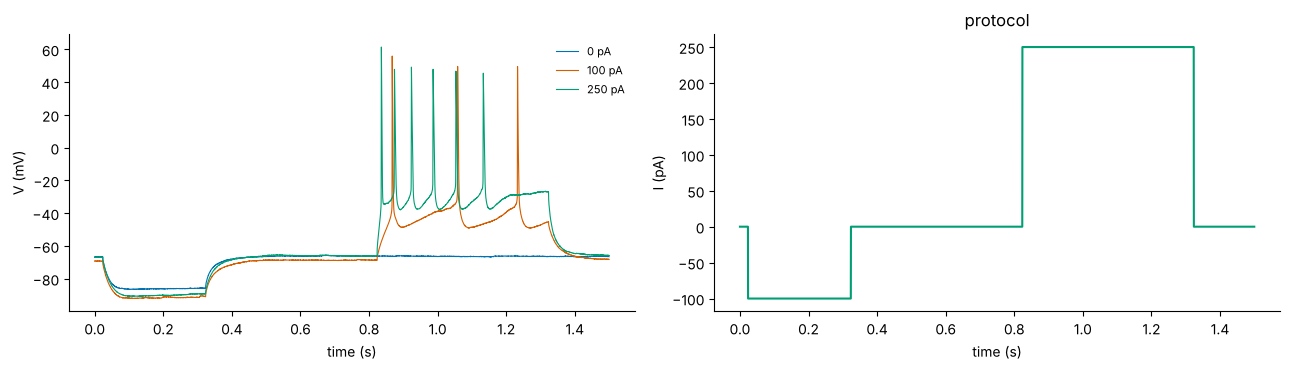

In [2]:
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
dd = load('patch_18711001_steps.npz')
V, I = dd['v_cmV'] / 100, dd['i_pA'].astype(float)
fs = float(dd['fs_hz']); t = np.arange(V.shape[1]) / fs
step_pA = np.round(I[:, int(1.0 * fs)])                       # (30,) current of the main step
print("V:", V.shape, "mV;  steps (pA):", step_pA[:4], "...", step_pA[-1])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for s, c in zip([0, 10, 25], PALETTE):
    axes[0].plot(t, V[s], color=c, lw=0.8, label=f'{step_pA[s]:.0f} pA')
axes[0].set_xlabel('time (s)'); axes[0].set_ylabel('V (mV)'); axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(t, I[25], color=PALETTE[2]); axes[1].set_xlabel('time (s)'); axes[1].set_ylabel('I (pA)'); axes[1].set_title('protocol')
plt.tight_layout(); plt.show()

### Worked first step: the passive response of one sweep

In [3]:
on = (t >= 0.0235) & (t < 0.323)                              # during the -100 pA step
def charge(tt, V_inf, dV, tau):
    return V_inf + dV * np.exp(-tt / tau)
s = 0
tt = t[on] - t[on][0]
(Vinf, dV, tau), _ = curve_fit(charge, tt, V[s, on], p0=[V[s, on][-1], 5, 0.02], bounds=([-150, -50, 1e-4], [0, 50, 1]))
V_rest = V[s, t < 0.02].mean()
print(f"sweep {s}: rest {V_rest:.1f} mV, steady state {Vinf:.1f} mV, tau = {tau * 1000:.1f} ms, R = {(Vinf - V_rest) * 1e-3 / -100e-12 / 1e6:.0f} MOhm")

sweep 0: rest -66.7 mV, steady state -86.1 mV, tau = 15.1 ms, R = 194 MOhm


In [4]:
# TODO 1 -- Repeat the passive fit for all 30 sweeps; store the medians tau_m (s), R_in (ohm) and E_L (mV, resting potential).
tau_m = R_in = E_L = None

In [5]:
if todo(tau_m, R_in, E_L):
    print('TODO 1 not done yet.')
else:
    assert 0.001 < tau_m < 0.2 and R_in > 0 and -90 < E_L < -40
    print('Check 1 passed.')

TODO 1 not done yet.


In [6]:
# TODO 2 -- The measured f-I curve: store rate_meas (30,), spikes per second during the 0.5 s main step (count peaks above
# 0 mV between 0.823 and 1.323 s).
rate_meas = None

In [7]:
if todo(rate_meas):
    print('TODO 2 not done yet.')
else:
    assert np.shape(rate_meas) == (30,) and rate_meas[0] == 0
    print('Check 2 passed.')

TODO 2 not done yet.


In [8]:
# TODO 3 -- A LIF with tau_m, R_in and E_L fixed. Its rate for a constant current I (Lesson 22), with refractory period
# t_ref = 2 ms, is
#   f = 1 / (t_ref + tau_m * log((E_L + R I - V_reset) / (E_L + R I - V_th)))   if E_L + R I > V_th, else 0.
# (a) Set V_th from the rheobase: E_L + R I at the midpoint between the largest silent and the smallest spiking current.
# (b) Choose V_reset on a grid from -80 mV to V_th - 0.5 mV (steps of 0.5 mV) to minimise the squared error against rate_meas.
# Store V_th_fit, V_reset_fit and rate_lif (30,); plot both curves. Where does the LIF fail, and why?
V_th_fit = V_reset_fit = rate_lif = None

In [9]:
if todo(V_th_fit, V_reset_fit, rate_lif):
    print('TODO 3 not done yet.')
else:
    assert V_reset_fit < V_th_fit and np.shape(rate_lif) == (30,)
    print('Check 3 passed.')

TODO 3 not done yet.


### Before the talk
- The passive fit assumes one exponential; check the residuals, and say whether the cell sags (an h-current would show as a dip back).
- The measured rate is a count in 0.5 s: it moves in steps of 2 spikes/s.
- Expect a large failure: with the measured passive values, a LIF fires several times faster than this cell at strong currents, whatever the reset. Look at the intervals within each train: the cell slows down (adaptation), which a LIF cannot do. That failure is a result, not a mistake.